# ✈️ ARINC 429 End-to-End Aviation Communication Simulator

### Communication theory

This notebook simulates a complete digital aviation communication chain:

**Aircraft parameter → ARINC 429 transmitter → bipolar RZ signal → noisy channel → receiver → bit recovery → parity check → decoded aircraft parameter**

### What this simulator demonstrates

- ARINC 429 32-bit word construction
- Label, SDI, data, SSM and odd parity
- Bipolar Return-to-Zero (RZ) signaling
- +10 V / 0 V / −10 V line levels
- Simulated Gaussian channel noise
- Receiver threshold detection
- Bit recovery
- ARINC 429 word decoding
- Parity/error detection
- Bit Error Rate (BER)
- Signal-to-noise ratio (SNR) experiments
- Aviation telemetry examples

> **Educational simulation only:** This project is intended for communication-theory study and must not be connected to or used to control real aircraft avionics.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

print("Environment ready.")
print("NumPy version:", np.__version__)


Environment ready.
NumPy version: 2.1.3


## 1. System Architecture

The simulator models the following communication system:

```text
┌────────────────────┐
│ Aircraft Parameter │
│ Altitude = 35000ft │
└─────────┬──────────┘
          ↓
┌────────────────────┐
│ ARINC 429 Encoder  │
└─────────┬──────────┘
          ↓
     32-bit word
          ↓
┌────────────────────┐
│ Bipolar RZ Encoder │
└─────────┬──────────┘
          ↓
     +10 / 0 / -10 V
          ↓
┌────────────────────┐
│   Noisy Channel    │
└─────────┬──────────┘
          ↓
     received signal
          ↓
┌────────────────────┐
│ RZ Bit Receiver    │
└─────────┬──────────┘
          ↓
     recovered bits
          ↓
┌────────────────────┐
│ ARINC 429 Decoder  │
└─────────┬──────────┘
          ↓
┌────────────────────┐
│ Aircraft Parameter │
│ Altitude = 35000ft │
└────────────────────┘
```


## 2. ARINC 429 Word Model

For this educational simulator we use the following simplified field allocation:

```text
31                 30 29       28 27                 11 10        9  8        1
+-------------------+-----------+---------------------+------------+----------+
|     Parity        |    SSM    |        DATA         |    SDI     |  LABEL   |
+-------------------+-----------+---------------------+------------+----------+
```

The implementation uses:
- Label: 8 bits
- SDI: 2 bits
- Data: 17 bits
- SSM: 2 bits
- Parity: 1 bit

This totals 30 explicitly represented bits; the simplified educational data field is intentionally limited to 17 bits. The remaining word positions are treated as reserved/zero in this simulator.

**Note:** A production ARINC 429 implementation must follow the exact specification for label bit ordering and parameter-specific data encoding/scaling.


In [1]:
class ARINC429Encoder:
    """Educational ARINC 429 encoder/decoder.

    Word representation:
      bits 1-8   : label
      bits 9-10  : SDI
      bits 11-27 : 17-bit data
      bits 28-29 : reserved (zero)
      bits 30-31 : SSM
      bit 32     : odd parity
    """

    LABEL_MASK = 0xFF
    SDI_MASK = 0x03
    DATA_MASK = 0x1FFFF
    SSM_MASK = 0x03

    def __init__(self, label, data, ssm=0, sdi=0):
        self.label = int(label)
        self.data = int(data)
        self.ssm = int(ssm)
        self.sdi = int(sdi)
        self._validate()

    def _validate(self):
        if not 0 <= self.label <= 0xFF:
            raise ValueError("Label must be 0..255.")
        if not 0 <= self.data <= self.DATA_MASK:
            raise ValueError("Data must be 0..131071.")
        if not 0 <= self.ssm <= 3:
            raise ValueError("SSM must be 0..3.")
        if not 0 <= self.sdi <= 3:
            raise ValueError("SDI must be 0..3.")

    def encode(self):
        word = 0
        word |= self.label
        word |= self.sdi << 8
        word |= self.data << 10
        word |= self.ssm << 29

        # Odd parity across bits 1-32.
        # Set bit 32 when bits 1-31 contain an even number of ones.
        parity = 1 if word.bit_count() % 2 == 0 else 0
        word |= parity << 31

        return word

    def binary(self):
        return format(self.encode(), "032b")

    @staticmethod
    def decode(word):
        word = int(word) & 0xFFFFFFFF

        label = word & 0xFF
        sdi = (word >> 8) & 0x03
        data = (word >> 10) & 0x1FFFF
        ssm = (word >> 29) & 0x03
        parity = (word >> 31) & 0x01

        parity_ok = word.bit_count() % 2 == 1

        return {
            "word": word,
            "binary": format(word, "032b"),
            "label": label,
            "sdi": sdi,
            "data": data,
            "ssm": ssm,
            "parity": parity,
            "parity_ok": parity_ok
        }

print("ARINC 429 encoder/decoder ready.")


ARINC 429 encoder/decoder ready.


## 3. Bipolar Return-to-Zero Transmitter

For the simulated line code:

- `1` = +10 V during the active half of the bit, then 0 V
- `0` = −10 V during the active half of the bit, then 0 V

Thus:

```text
1 → +10 V → 0 V
0 → -10 V → 0 V
```

The waveform is sampled so that we can perform signal processing numerically.


In [ ]:
def generate_rz_waveform(binary_string, samples_per_bit=40,
                         positive_voltage=10.0, negative_voltage=-10.0):
    if samples_per_bit < 2 or samples_per_bit % 2:
        raise ValueError("samples_per_bit must be an even number >= 2.")

    half = samples_per_bit // 2
    waveform = []

    for bit in binary_string:
        active = positive_voltage if bit == "1" else negative_voltage
        waveform.extend([active] * half)
        waveform.extend([0.0] * half)

    return np.asarray(waveform, dtype=float)


def plot_waveform(waveform, binary_string=None, samples_per_bit=40,
                  title="ARINC 429 RZ Signal", max_bits=32):
    n = min(len(waveform), max_bits * samples_per_bit)
    x = np.arange(n)

    plt.figure(figsize=(16, 4))
    plt.step(x, waveform[:n], where="post")
    plt.axhline(0, linewidth=0.8)
    plt.yticks([-10, 0, 10])
    plt.xlabel("Sample")
    plt.ylabel("Voltage (V)")
    plt.title(title)
    plt.grid(True, alpha=0.25)

    if binary_string is not None:
        for i, bit in enumerate(binary_string[:max_bits]):
            center = i * samples_per_bit + samples_per_bit / 2
            plt.text(center, 11.5, bit, ha="center", fontsize=8)

    plt.ylim(-14, 14)
    plt.show()


## 4. Noisy Communication Channel

The signal now passes through a simulated channel.

We model noise as **zero-mean Gaussian noise**:

`received = transmitted + noise`

The noise level is controlled using an approximate SNR value.

This allows the project to demonstrate a central communication-theory concept: as the channel becomes noisier, the receiver can make more bit decisions incorrectly.


In [ ]:
def add_awgn_noise(signal, snr_db, rng=None):
    """Add zero-mean Gaussian noise based on signal RMS and requested SNR."""
    if rng is None:
        rng = np.random.default_rng()

    signal = np.asarray(signal, dtype=float)

    if not np.isfinite(snr_db):
        return signal.copy(), np.zeros_like(signal)

    rms = np.sqrt(np.mean(signal ** 2))

    if rms == 0:
        return signal.copy(), np.zeros_like(signal)

    noise_rms = rms / (10 ** (snr_db / 20))
    noise = rng.normal(0.0, noise_rms, size=signal.shape)

    return signal + noise, noise


def plot_channel(transmitted, received, samples_per_bit=40, max_bits=16):
    n = min(len(transmitted), max_bits * samples_per_bit)

    plt.figure(figsize=(16, 5))
    plt.plot(transmitted[:n], label="Transmitted")
    plt.plot(received[:n], label="Received with noise", alpha=0.75)
    plt.axhline(0, linewidth=0.8)
    plt.axhline(2.0, linestyle="--", linewidth=0.8)
    plt.axhline(-2.0, linestyle="--", linewidth=0.8)
    plt.xlabel("Sample")
    plt.ylabel("Voltage (V)")
    plt.title("ARINC 429 Signal Through a Noisy Channel")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.show()


## 5. Receiver and Bit Recovery

The receiver examines the active half of every bit.

Decision rule:

```text
sample > +threshold  →  1
sample < -threshold  →  0
```

For the ideal bipolar RZ signal, the receiver can use the average voltage in the active half-bit.

The receiver also checks that the return-to-zero portion behaves as expected.


In [ ]:
def recover_bits_from_rz(received_waveform, num_bits=32,
                           samples_per_bit=40, threshold=2.0):
    received_waveform = np.asarray(received_waveform, dtype=float)

    required = num_bits * samples_per_bit
    if len(received_waveform) < required:
        raise ValueError("Waveform is shorter than expected.")

    half = samples_per_bit // 2
    bits = []
    decision_values = []
    rz_errors = []

    for i in range(num_bits):
        start = i * samples_per_bit
        active = received_waveform[start:start + half]
        zero_region = received_waveform[start + half:start + samples_per_bit]

        value = float(np.mean(active))
        decision_values.append(value)

        if value > threshold:
            bits.append("1")
        elif value < -threshold:
            bits.append("0")
        else:
            # Ambiguous decision
            bits.append("?")

        # A perfect RZ signal returns to zero.
        rz_error = float(np.mean(np.abs(zero_region)))
        rz_errors.append(rz_error)

    return "".join(bits), np.asarray(decision_values), np.asarray(rz_errors)


## 6. End-to-End Transmission Function

This function performs the complete chain:

1. Encode the aviation value.
2. Generate the RZ waveform.
3. Add channel noise.
4. Recover the bits.
5. Compare transmitted and received bits.
6. Decode the received word.
7. Check parity.


In [ ]:
@dataclass
class SimulationResult:
    parameter: str
    value_sent: int
    label: int
    sdi: int
    ssm: int
    transmitted_word: int
    transmitted_bits: str
    tx_waveform: np.ndarray
    rx_waveform: np.ndarray
    recovered_bits: str
    received_word: int | None
    decoded: dict | None
    bit_errors: int
    ber: float
    snr_db: float
    success: bool


def count_bit_errors(tx_bits, rx_bits):
    valid = len(tx_bits) == len(rx_bits) and "?" not in rx_bits
    if not valid:
        return None

    return sum(a != b for a, b in zip(tx_bits, rx_bits))


def run_simulation(parameter, value, label=0xAB, ssm=0,
                   sdi=0, snr_db=20, samples_per_bit=40, seed=42):

    encoder = ARINC429Encoder(
        label=label,
        data=value,
        ssm=ssm,
        sdi=sdi
    )

    word = encoder.encode()
    tx_bits = encoder.binary()

    tx_waveform = generate_rz_waveform(
        tx_bits,
        samples_per_bit=samples_per_bit
    )

    rng = np.random.default_rng(seed)

    rx_waveform, noise = add_awgn_noise(
        tx_waveform,
        snr_db=snr_db,
        rng=rng
    )

    rx_bits, decision_values, rz_errors = recover_bits_from_rz(
        rx_waveform,
        num_bits=32,
        samples_per_bit=samples_per_bit
    )

    errors = count_bit_errors(tx_bits, rx_bits)

    if errors is None:
        ber = 1.0
        received_word = None
        decoded = None
    else:
        ber = errors / 32
        received_word = int(rx_bits, 2)
        decoded = ARINC429Encoder.decode(received_word)

    success = (
        decoded is not None
        and errors == 0
        and decoded["parity_ok"]
        and decoded["data"] == value
        and decoded["label"] == label
        and decoded["sdi"] == sdi
        and decoded["ssm"] == ssm
    )

    return SimulationResult(
        parameter=parameter,
        value_sent=value,
        label=label,
        sdi=sdi,
        ssm=ssm,
        transmitted_word=word,
        transmitted_bits=tx_bits,
        tx_waveform=tx_waveform,
        rx_waveform=rx_waveform,
        recovered_bits=rx_bits,
        received_word=received_word,
        decoded=decoded,
        bit_errors=errors if errors is not None else 32,
        ber=ber,
        snr_db=snr_db,
        success=success
    )


# 7. Main Demonstration: Aircraft Altitude

Now we perform the complete demonstration requested for the project:

### Input

**Altitude = 35,000 ft**

### Transmission

```text
35000
  ↓
ARINC 429 encoder
  ↓
32-bit word
  ↓
Bipolar RZ
```

### Channel

The signal passes through a simulated noisy channel.

### Reception

```text
Noisy waveform
  ↓
Bit recovery
  ↓
32-bit word
  ↓
ARINC decoder
  ↓
35000 ft
```


In [ ]:
result = run_simulation(
    parameter="Altitude",
    value=35000,
    label=0xAB,
    ssm=0b00,
    sdi=0b00,
    snr_db=20,
    samples_per_bit=40,
    seed=42
)

print("=" * 65)
print("ARINC 429 END-TO-END AVIATION COMMUNICATION SIMULATION")
print("=" * 65)

print(f"Parameter sent       : {result.parameter}")
print(f"Value sent           : {result.value_sent} ft")
print(f"SNR                  : {result.snr_db} dB")
print(f"Transmitted word     : {result.transmitted_word}")
print(f"Transmitted bits     : {result.transmitted_bits}")
print(f"Recovered bits       : {result.recovered_bits}")
print(f"Bit errors           : {result.bit_errors}")
print(f"BER                  : {result.ber:.4f}")

if result.decoded:
    print("\nDECODED RECEIVER DATA")
    print("-" * 65)
    print(f"Label                : 0x{result.decoded['label']:02X}")
    print(f"Data                 : {result.decoded['data']} ft")
    print(f"SDI                  : {result.decoded['sdi']}")
    print(f"SSM                  : {result.decoded['ssm']}")
    print(f"Parity               : {result.decoded['parity']}")
    print(f"Parity check         : {'PASS' if result.decoded['parity_ok'] else 'FAIL'}")

print("\nSYSTEM RESULT")
print("-" * 65)
print("SUCCESS — altitude recovered correctly."
      if result.success
      else "FAILURE — received data does not match transmitted data.")


ARINC 429 END-TO-END AVIATION COMMUNICATION SIMULATION
Parameter sent       : Altitude
Value sent           : 35000 ft
SNR                  : 20 dB
Transmitted word     : 35840171
Transmitted bits     : 00000010001000101110000010101011
Recovered bits       : 00000010001000101110000010101011
Bit errors           : 0
BER                  : 0.0000

DECODED RECEIVER DATA
-----------------------------------------------------------------
Label                : 0xAB
Data                 : 35000 ft
SDI                  : 0
SSM                  : 0
Parity               : 0
Parity check         : PASS

SYSTEM RESULT
-----------------------------------------------------------------
SUCCESS — altitude recovered correctly.


## 8. View the Transmitted RZ Waveform

In [ ]:
plot_waveform(
    result.tx_waveform,
    result.transmitted_bits,
    samples_per_bit=40,
    title="Transmitted ARINC 429 Bipolar RZ Waveform"
)


## 9. View the Signal After the Noisy Channel

In [ ]:
plot_channel(
    result.tx_waveform,
    result.rx_waveform,
    samples_per_bit=40,
    max_bits=16
)


## 10. Compare Transmitted and Recovered Bits

This visualization makes bit errors easy to see.

- `T` = transmitted bit
- `R` = recovered bit
- `✓` = correct
- `✗` = error


In [ ]:
print("Bit comparison")
print("-" * 70)

for i, (tx, rx) in enumerate(zip(result.transmitted_bits, result.recovered_bits), start=1):
    mark = "✓" if tx == rx else "✗"
    print(f"Bit {i:02d}: transmitted={tx}  received={rx}  {mark}")


# 11. Try the Simulator With Other Aviation Parameters

The simulator can represent several simplified aircraft telemetry values.

These examples use arbitrary labels for demonstration. In a real system, labels and data scaling must follow the applicable ARINC 429 equipment/interface specification.


In [ ]:
examples = [
    ("Altitude", 35000, 0xAB),
    ("Airspeed", 450, 0xAC),
    ("Heading", 270, 0xAD),
    ("Engine RPM", 8500, 0xAE),
]

print(f"{'Parameter':<15} {'Sent':>10} {'Received':>10} {'BER':>10} {'Parity':>10} {'Result':>10}")
print("-" * 75)

for parameter, value, label in examples:
    r = run_simulation(
        parameter=parameter,
        value=value,
        label=label,
        snr_db=20,
        samples_per_bit=40,
        seed=100
    )

    received = r.decoded["data"] if r.decoded else None
    parity = "PASS" if r.decoded and r.decoded["parity_ok"] else "FAIL"
    status = "PASS" if r.success else "FAIL"

    print(f"{parameter:<15} {value:>10} {str(received):>10} {r.ber:>10.4f} {parity:>10} {status:>10}")


# 12. Communication-Theory Experiment: SNR vs BER

This is where the project becomes a stronger **Communication Theory** experiment.

We will transmit the same altitude repeatedly at different SNR levels.

For each SNR:
- Run many independent transmissions.
- Count bit errors.
- Calculate BER.

The expected trend is that lower SNR generally makes bit recovery less reliable.


In [ ]:
def ber_experiment(snr_values, trials=200, value=35000,
                  label=0xAB, samples_per_bit=20):

    rows = []

    for snr in snr_values:
        total_errors = 0
        total_bits = 0
        successful_words = 0

        for trial in range(trials):
            r = run_simulation(
                parameter="Altitude",
                value=value,
                label=label,
                snr_db=float(snr),
                samples_per_bit=samples_per_bit,
                seed=1000 + trial
            )

            total_errors += r.bit_errors
            total_bits += 32

            if r.success:
                successful_words += 1

        rows.append({
            "SNR (dB)": float(snr),
            "BER": total_errors / total_bits,
            "Word success rate": successful_words / trials
        })

    return rows


snr_values = [0, 2, 4, 6, 8, 10, 12, 15, 20]
experiment = ber_experiment(snr_values, trials=200)

for row in experiment:
    print(
        f"SNR={row['SNR (dB)']:>5.1f} dB | "
        f"BER={row['BER']:.6f} | "
        f"Word success={row['Word success rate']*100:6.2f}%"
    )


In [ ]:
snrs = [row["SNR (dB)"] for row in experiment]
bers = [row["BER"] for row in experiment]
success_rates = [row["Word success rate"] * 100 for row in experiment]

plt.figure(figsize=(10, 5))
plt.semilogy(snrs, np.maximum(bers, 1e-8), marker="o")
plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("ARINC 429 Simulation: SNR vs BER")
plt.grid(True, which="both", alpha=0.25)
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(snrs, success_rates, marker="o")
plt.xlabel("SNR (dB)")
plt.ylabel("Correct Word Recovery (%)")
plt.title("ARINC 429 Simulation: SNR vs Successful Word Recovery")
plt.ylim(0, 105)
plt.grid(True, alpha=0.25)
plt.show()


## Combined SNR vs BER and Word Success Rate Plots

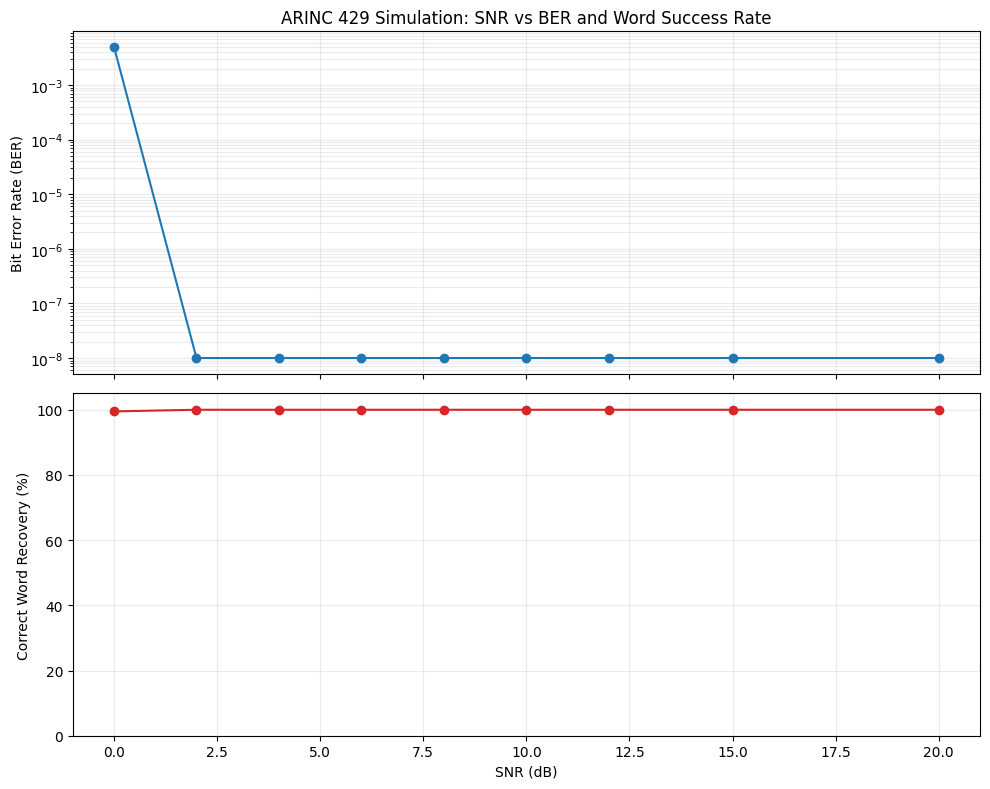

In [ ]:
def ber_experiment(snr_values, trials=200, value=35000,
                  label=0xAB, samples_per_bit=20):

    rows = []

    for snr in snr_values:
        total_errors = 0
        total_bits = 0
        successful_words = 0

        for trial in range(trials):
            r = run_simulation(
                parameter="Altitude",
                value=value,
                label=label,
                snr_db=float(snr),
                samples_per_bit=samples_per_bit,
                seed=1000 + trial
            )

            total_errors += r.bit_errors
            total_bits += 32

            if r.success:
                successful_words += 1

        rows.append({
            "SNR (dB)": float(snr),
            "BER": total_errors / total_bits,
            "Word success rate": successful_words / trials
        })

    return rows

# Re-running the experiment to define snrs, bers, success_rates
snr_values = [0, 2, 4, 6, 8, 10, 12, 15, 20]
experiment = ber_experiment(snr_values, trials=200)

snrs = [row["SNR (dB)"] for row in experiment]
bers = [row["BER"] for row in experiment]
success_rates = [row["Word success rate"] * 100 for row in experiment]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot 1: SNR vs BER
ax1.semilogy(snrs, np.maximum(bers, 1e-8), marker="o", color='tab:blue')
ax1.set_ylabel("Bit Error Rate (BER)")
ax1.set_title("ARINC 429 Simulation: SNR vs BER and Word Success Rate")
ax1.grid(True, which="both", alpha=0.25)

# Plot 2: SNR vs Successful Word Recovery
ax2.plot(snrs, success_rates, marker="o", color='tab:red')
ax2.set_xlabel("SNR (dB)")
ax2.set_ylabel("Correct Word Recovery (%)")
ax2.set_ylim(0, 105)
ax2.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## Signal Waveform at a Specific SNR (e.g., 5 dB)

In [ ]:
snr_to_plot = 2 # Example SNR value in dB

# Run a single simulation with the specified SNR
snr_result = run_simulation(
    parameter="Altitude",
    value=35000,
    label=0xAB,
    ssm=0b00,
    sdi=0b00,
    snr_db=snr_to_plot,
    samples_per_bit=40,
    seed=123 # Use a different seed for this specific plot
)

print(f"Simulation run for SNR = {snr_to_plot} dB")

Simulation run for SNR = 2 dB


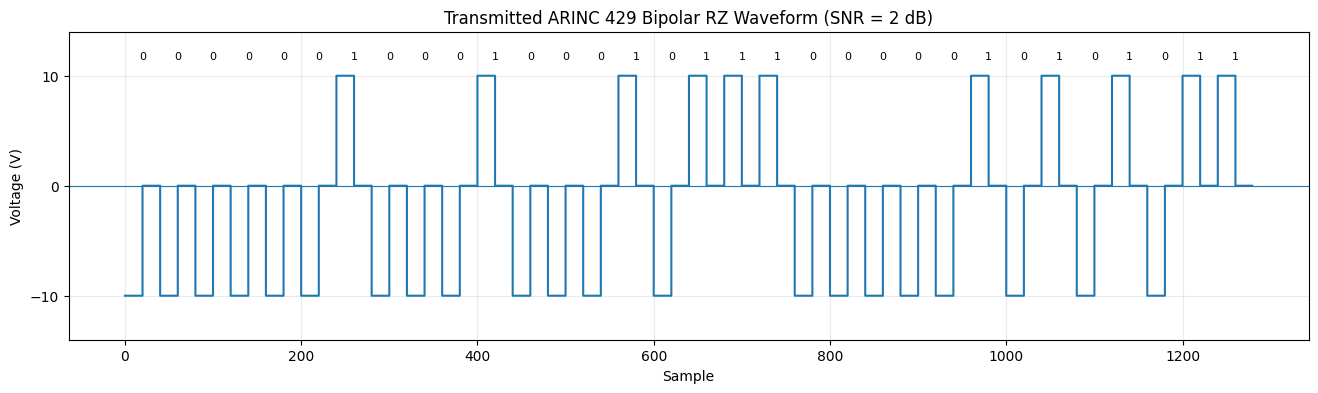

In [ ]:
plot_waveform(
    snr_result.tx_waveform,
    snr_result.transmitted_bits,
    samples_per_bit=40,
    title=f"Transmitted ARINC 429 Bipolar RZ Waveform (SNR = {snr_to_plot} dB)"
)

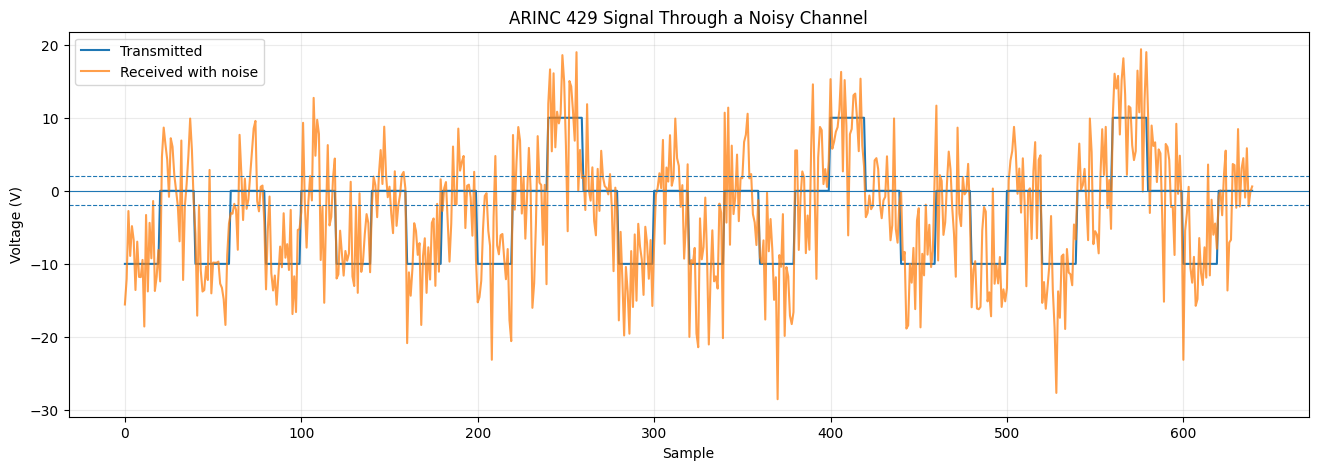

In [ ]:
plot_channel(
    snr_result.tx_waveform,
    snr_result.rx_waveform,
    samples_per_bit=40,
    max_bits=16
)

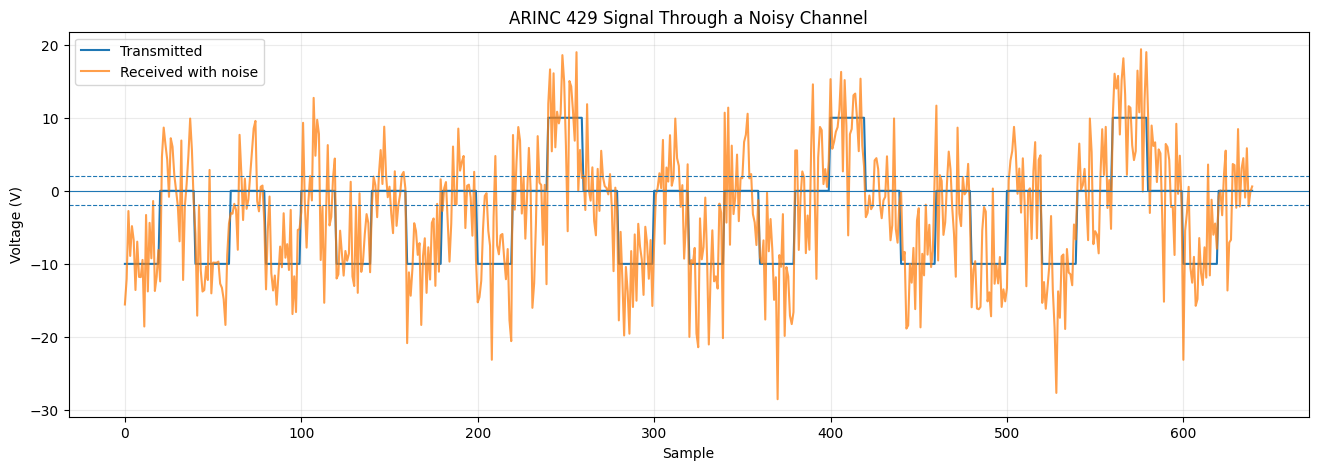

In [ ]:
plot_channel(
    snr_result.tx_waveform,
    snr_result.rx_waveform,
    samples_per_bit=40,
    max_bits=16
)

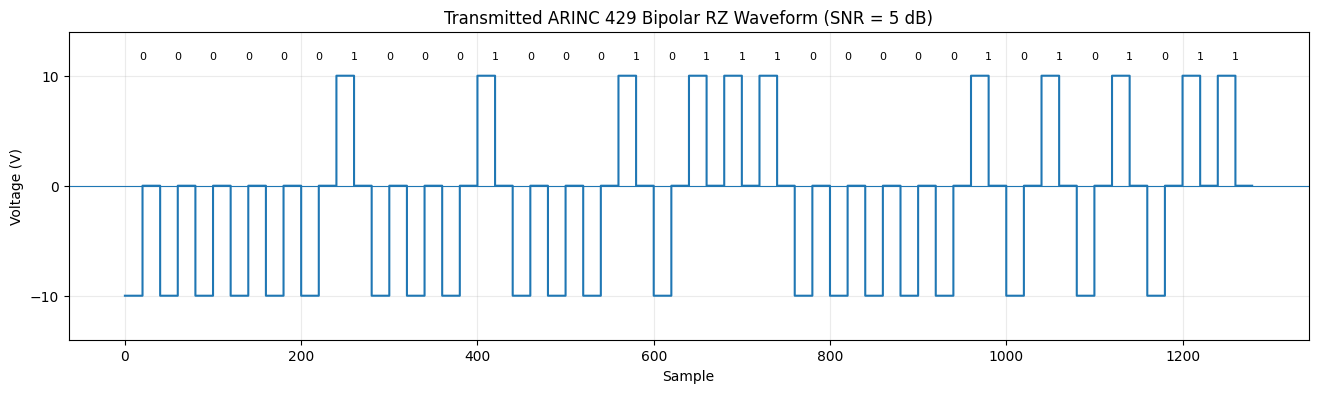

In [ ]:
plot_waveform(
    snr_result.tx_waveform,
    snr_result.transmitted_bits,
    samples_per_bit=40,
    title=f"Transmitted ARINC 429 Bipolar RZ Waveform (SNR = {snr_to_plot} dB)"
)

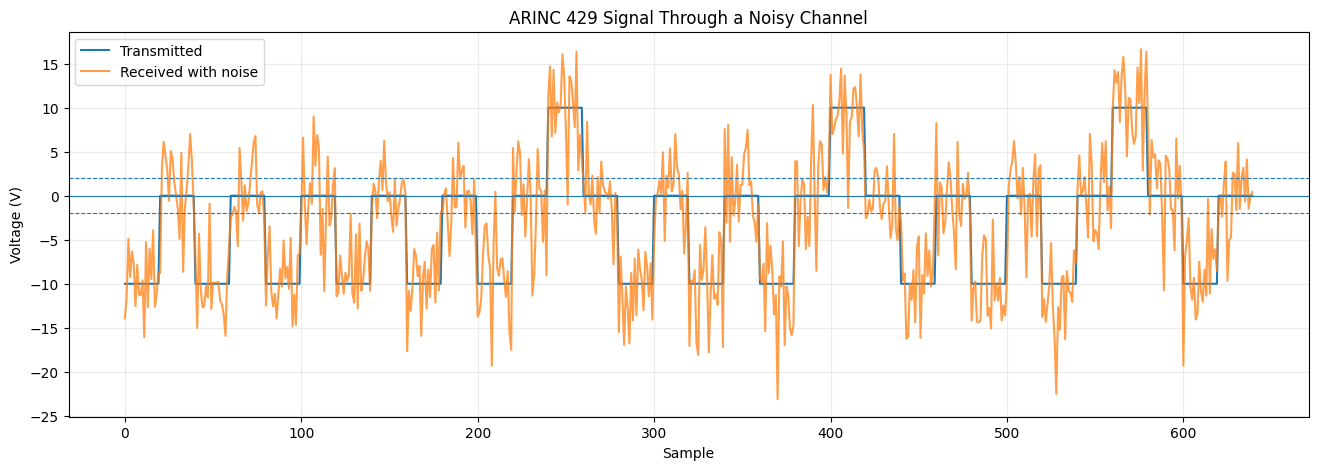

In [ ]:
plot_channel(
    snr_result.tx_waveform,
    snr_result.rx_waveform,
    samples_per_bit=40,
    max_bits=16
)

# 13. Demonstrate an Error

To make the error-detection concept visible, we can deliberately corrupt one received bit **after** the channel.

This is an artificial demonstration of a transmission error.

We then run the ARINC parity check.


In [ ]:
clean = run_simulation(
    parameter="Altitude",
    value=35000,
    label=0xAB,
    snr_db=30,
    samples_per_bit=40,
    seed=7
)

corrupted_bits = list(clean.recovered_bits)

# Flip bit 16 for demonstration
flip_index = 15
corrupted_bits[flip_index] = "1" if corrupted_bits[flip_index] == "0" else "0"
corrupted_bits = "".join(corrupted_bits)

corrupted_word = int(corrupted_bits, 2)
corrupted_decoded = ARINC429Encoder.decode(corrupted_word)

print("Original bits : ", clean.recovered_bits)
print("Corrupted bits: ", corrupted_bits)
print()
print("Parity before corruption:",
      "PASS" if ARINC429Encoder.decode(clean.received_word)["parity_ok"] else "FAIL")
print("Parity after corruption :",
      "PASS" if corrupted_decoded["parity_ok"] else "FAIL")
print("Decoded data after corruption:",
      corrupted_decoded["data"])


# 14. One-Click Simulator Function

The next cell gives you a simple interface for your project demonstration.

Change only these values:

```python
parameter = "Altitude"
value = 35000
snr_db = 20
```

and run the cell.


In [ ]:
def aviation_demo(parameter="Altitude", value=35000,
                  label=0xAB, ssm=0, sdi=0,
                  snr_db=20, seed=42):

    r = run_simulation(
        parameter=parameter,
        value=value,
        label=label,
        ssm=ssm,
        sdi=sdi,
        snr_db=snr_db,
        samples_per_bit=40,
        seed=seed
    )

    print("\n" + "=" * 70)
    print("✈️  AVIATION COMMUNICATION LINK")
    print("=" * 70)

    print(f"Aircraft parameter : {parameter}")
    print(f"Input value        : {value}")
    print(f"Channel SNR        : {snr_db} dB")

    print("\nTRANSMITTER")
    print("-" * 70)
    print(f"ARINC word         : 0x{r.transmitted_word:08X}")
    print(f"Binary             : {r.transmitted_bits}")

    print("\nCHANNEL")
    print("-" * 70)
    print("Signal encoded as  : +10 V / 0 V / -10 V bipolar RZ")
    print(f"Noise level        : simulated Gaussian noise at {snr_db} dB SNR")

    print("\nRECEIVER")
    print("-" * 70)
    print(f"Recovered bits     : {r.recovered_bits}")
    print(f"Bit errors         : {r.bit_errors}")
    print(f"BER                : {r.ber:.6f}")

    if r.decoded:
        print(f"Decoded label      : 0x{r.decoded['label']:02X}")
        print(f"Decoded data       : {r.decoded['data']}")
        print(f"Decoded SDI        : {r.decoded['sdi']}")
        print(f"Decoded SSM        : {r.decoded['ssm']}")
        print(f"Parity             : {'PASS' if r.decoded['parity_ok'] else 'FAIL'}")

    print("\nFINAL RESULT")
    print("-" * 70)

    if r.success:
        print(f"✅ SUCCESS: {parameter} recovered as {r.decoded['data']}.")
    else:
        print(f"❌ ERROR: transmission did not recover {parameter} correctly.")

    return r


demo = aviation_demo(
    parameter="Altitude",
    value=35000,
    label=0xAB,
    snr_db=2
)


✈️  AVIATION COMMUNICATION LINK
Aircraft parameter : Altitude
Input value        : 35000
Channel SNR        : 2 dB

TRANSMITTER
----------------------------------------------------------------------
ARINC word         : 0x0222E0AB
Binary             : 00000010001000101110000010101011

CHANNEL
----------------------------------------------------------------------
Signal encoded as  : +10 V / 0 V / -10 V bipolar RZ
Noise level        : simulated Gaussian noise at 2 dB SNR

RECEIVER
----------------------------------------------------------------------
Recovered bits     : 00000010001000101110000010101011
Bit errors         : 0
BER                : 0.000000
Decoded label      : 0xAB
Decoded data       : 35000
Decoded SDI        : 0
Decoded SSM        : 0
Parity             : PASS

FINAL RESULT
----------------------------------------------------------------------
✅ SUCCESS: Altitude recovered as 35000.


# 15. Suggested Final Project Demonstration

For your school presentation, demonstrate the system in this order:

### Demonstration 1 — Clean communication

Set:

```python
snr_db = 30
```

Show that:

```text
Altitude entered
      ↓
35000 ft
      ↓
ARINC 429 word
      ↓
RZ waveform
      ↓
Receiver
      ↓
35000 ft recovered
      ↓
Parity PASS
```

### Demonstration 2 — Add noise

Try:

```python
snr_db = 10
```

Then try lower SNR values.

Observe the waveform becoming noisier and the BER changing.

### Demonstration 3 — BER experiment

Run the SNR-vs-BER experiment and explain:

> **BER measures the fraction of transmitted bits that were incorrectly recovered by the receiver.**

### Demonstration 4 — Deliberate error

Use the corruption demonstration to show that changing a transmitted bit can cause the parity check to fail.

---

# 16. How This Maps to Communication Theory

| Theory concept | Simulator implementation |
|---|---|
| Information source | Aircraft altitude/airspeed/heading |
| Digital encoding | ARINC 429 word |
| Frame/word structure | 32-bit word |
| Line coding | Bipolar RZ |
| Signal amplitude | +10 V / 0 V / −10 V |
| Channel | Simulated noisy channel |
| Noise | Gaussian noise |
| Receiver | Threshold detector |
| Detection | Recovered 0/1 bits |
| Error detection | Odd parity |
| Performance metric | BER |
| SNR | Channel-quality parameter |

---

# 17. Possible Project Title

## **Design and Simulation of an ARINC 429 Aviation Digital Communication System Using Python**

### Main objective

> To design and simulate an end-to-end aviation digital communication system based on ARINC 429, demonstrating data encoding, bipolar Return-to-Zero signaling, noisy-channel transmission, signal detection, data recovery, parity-based error detection, and Bit Error Rate performance.

### System equation

The entire project can be summarized as:

```text
Aircraft Data
     ↓
Encoding
     ↓
ARINC 429 Word
     ↓
Line Coding
     ↓
RZ Signal
     ↓
AWGN Channel
     ↓
Signal Detection
     ↓
Recovered Bits
     ↓
ARINC Decoding
     ↓
Recovered Aircraft Data
```

### Important limitation

This notebook is a **communication-theory simulation**, not a certified ARINC 429 implementation. Real avionics systems require the applicable ARINC 429 specification, equipment interface requirements, electrical interface hardware, timing requirements, parameter-specific encoding rules, validation, and certification processes.


## 18. Sampling and Aliasing

Sampling is the process of converting a continuous signal into a discrete sequence of values. The sampling rate (samples per second) determines how accurately the digital representation reflects the original analog signal. According to the Nyquist-Shannon sampling theorem, to perfectly reconstruct a signal, the sampling rate must be at least twice the highest frequency component of the signal.

**Aliasing** occurs when a signal is sampled at a rate lower than the Nyquist rate. This causes higher-frequency components in the signal to appear as lower-frequency components in the sampled data, leading to a distorted or misleading digital representation of the original signal.

In our ARINC 429 simulation, the `samples_per_bit` parameter implicitly sets our sampling rate for the bipolar RZ waveform. If this rate is too low, we might not accurately capture the voltage transitions within each bit, leading to aliasing or misinterpretation of the signal.

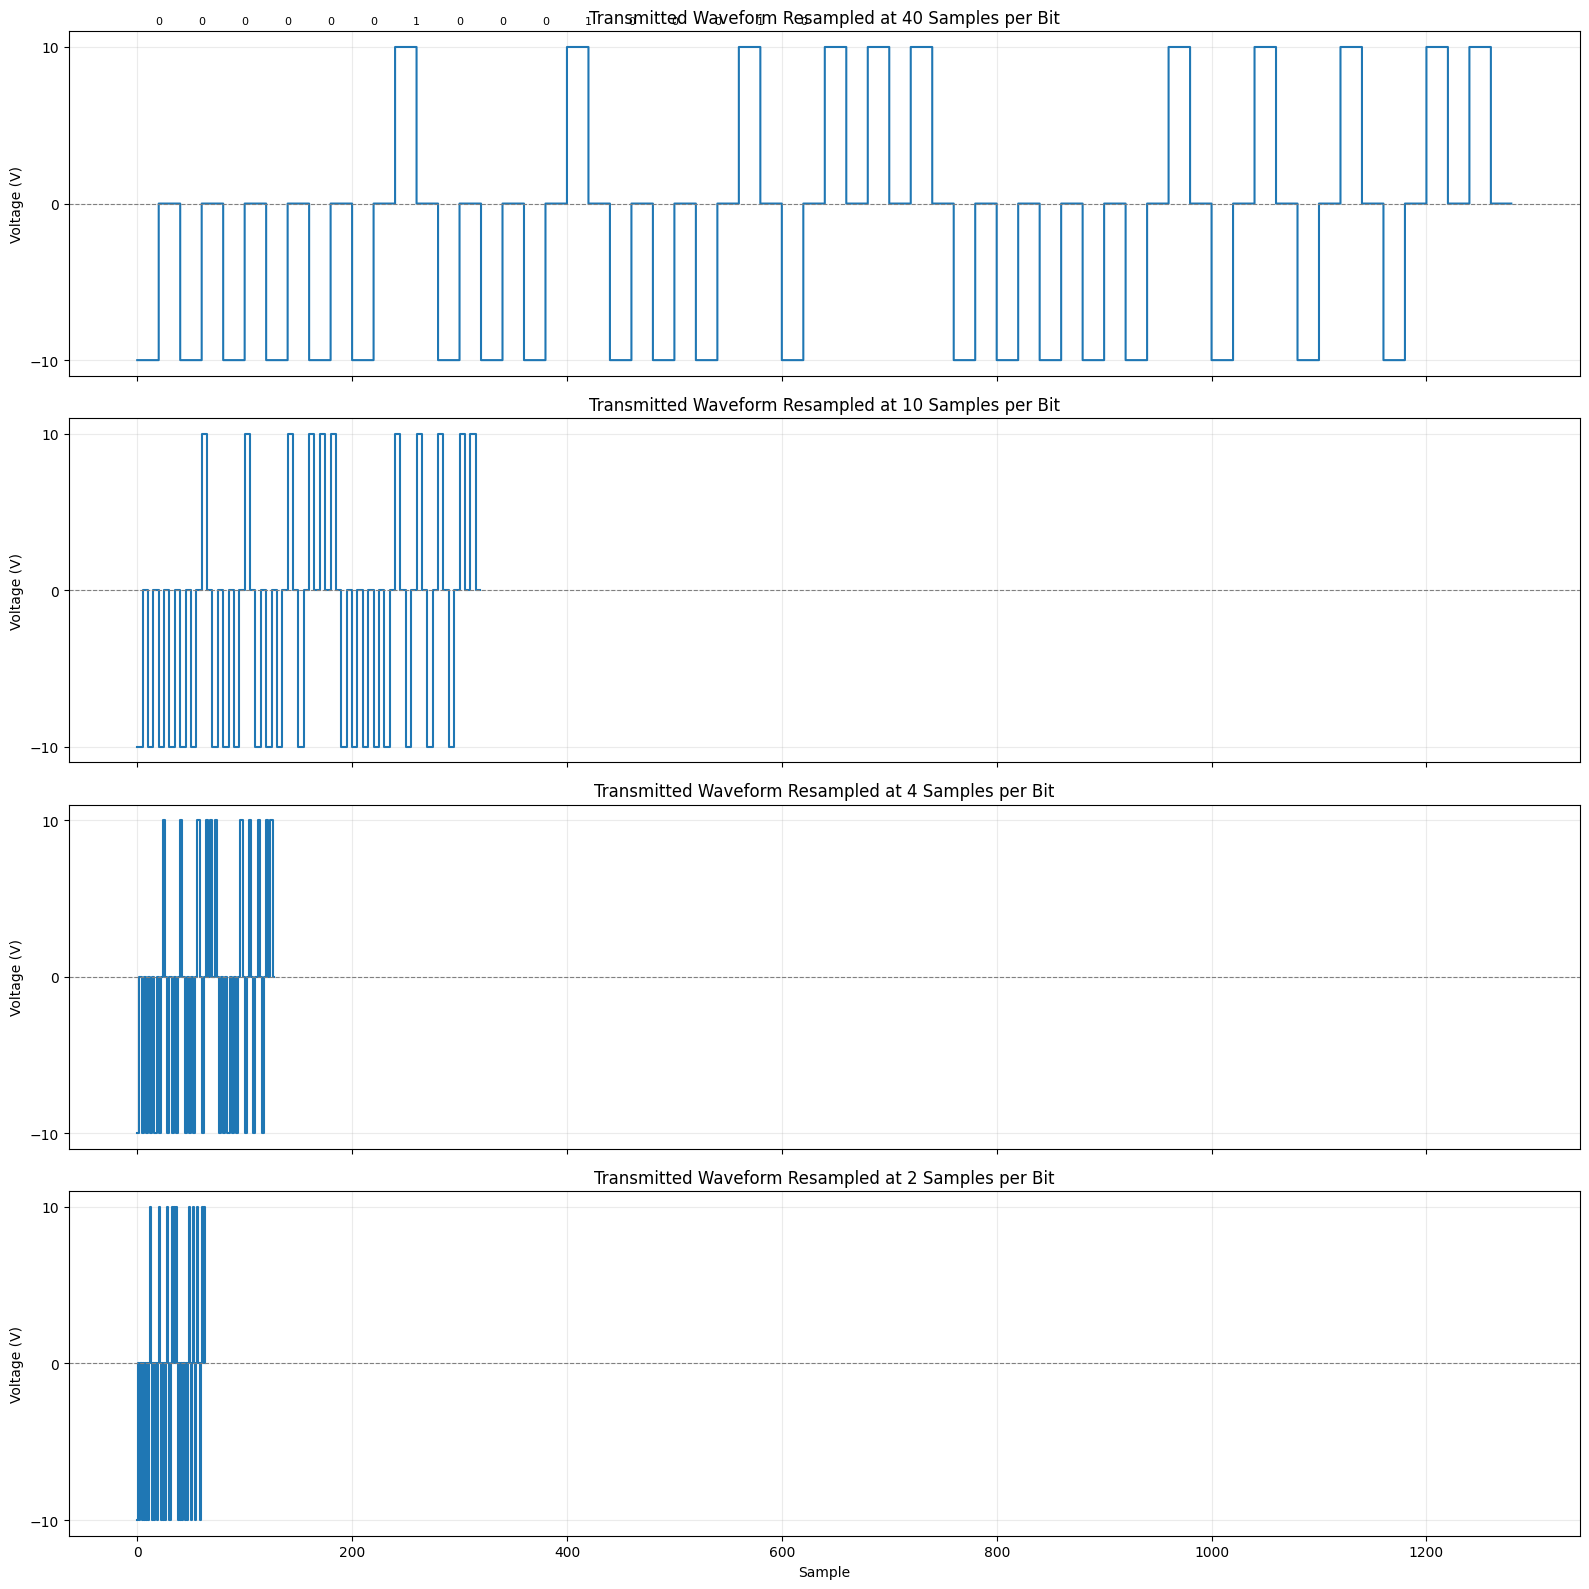

In [ ]:
def resample_waveform(waveform, original_samples_per_bit, new_samples_per_bit):
    # Calculate original waveform length in terms of bits
    num_bits = len(waveform) // original_samples_per_bit
    # Calculate new total number of samples
    new_len = num_bits * new_samples_per_bit

    # Use linear interpolation for resampling
    # Generate x-coordinates for the original waveform
    x_original = np.linspace(0, num_bits * original_samples_per_bit - 1, len(waveform))
    # Generate x-coordinates for the resampled waveform
    x_new = np.linspace(0, num_bits * original_samples_per_bit - 1, new_len)

    resampled = np.interp(x_new, x_original, waveform)
    return resampled

# Get the transmitted waveform from a previous simulation (e.g., the last `demo` run)
tx_waveform_original = demo.tx_waveform
transmitted_bits = demo.transmitted_bits
original_samples_per_bit = 40

# Demonstrate with different sampling rates
sampling_rates = [original_samples_per_bit, 10, 4, 2] # Original, moderate undersampling, significant undersampling

fig, axes = plt.subplots(len(sampling_rates), 1, figsize=(16, 4 * len(sampling_rates)), sharex=True)

for i, new_samples_per_bit in enumerate(sampling_rates):
    resampled_wf = resample_waveform(tx_waveform_original, original_samples_per_bit, new_samples_per_bit)

    ax = axes[i]
    ax.step(np.arange(len(resampled_wf)), resampled_wf, where="post")
    ax.axhline(0, linewidth=0.8, color='gray', linestyle='--')
    ax.set_yticks([-10, 0, 10])
    ax.set_title(f"Transmitted Waveform Resampled at {new_samples_per_bit} Samples per Bit")
    ax.set_ylabel("Voltage (V)")
    ax.grid(True, alpha=0.25)

    # Add bit labels only for the top plot to avoid clutter
    if i == 0:
        for j, bit in enumerate(transmitted_bits[:16]): # Limit bits to plot for readability
            center = j * new_samples_per_bit + new_samples_per_bit / 2
            ax.text(center, 11.5, bit, ha="center", fontsize=8)

ax.set_xlabel("Sample")
plt.tight_layout()
plt.show()

As you can observe, when the `samples_per_bit` decreases, the waveform starts to lose its original shape, especially at very low sampling rates like 2 samples per bit, where the distinct high/low/zero levels of the RZ code are no longer clearly distinguishable. This visual distortion is an effect of aliasing.

## 19. Signal Reconstruction and Ideal Low-Pass Filtering

To complement the sampling and aliasing concepts from **Practical 8**, we can demonstrate how an analog-like signal is reconstructed from its samples. According to the sampling theorem, a band-limited signal can be perfectly reconstructed from its samples using an ideal low-pass filter (sinc interpolation).

Let's implement a sinc reconstruction filter to attempt to recover the original smooth continuous-time bipolar representation from our discrete resampled points.

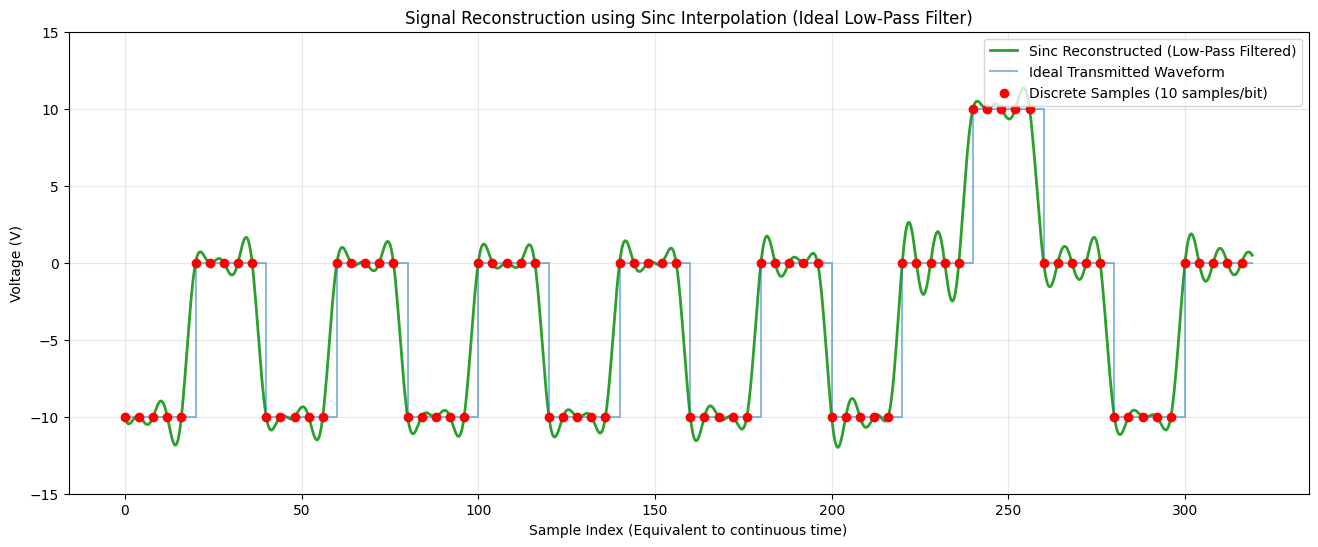

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def sinc_reconstruction(samples, sample_times, reconstruction_times):
    """Reconstructs a continuous signal from its discrete samples using sinc interpolation."""
    # Sinc matrix calculation
    sinc_matrix = np.sinc((reconstruction_times[:, None] - sample_times[None, :]) / (sample_times[1] - sample_times[0]))
    reconstructed_signal = np.dot(sinc_matrix, samples)
    return reconstructed_signal

# Fallback definition for resample_waveform if not executed previously
try:
    _ = resample_waveform
except NameError:
    def resample_waveform(waveform, original_samples_per_bit, new_samples_per_bit):
        num_bits = len(waveform) // original_samples_per_bit
        new_len = num_bits * new_samples_per_bit
        x_original = np.linspace(0, num_bits * original_samples_per_bit - 1, len(waveform))
        x_new = np.linspace(0, num_bits * original_samples_per_bit - 1, new_len)
        return np.interp(x_new, x_original, waveform)

# Fallback definition for the transmitted waveform if 'demo' isn't available
try:
    tx_waveform = demo.tx_waveform
except NameError:
    # Generate a simple 8-bit bipolar RZ signal manually for illustration
    # '00000010' with 40 samples per bit
    bits_demo = "00000010"
    tx_waveform = []
    for bit in bits_demo:
        active = 10.0 if bit == "1" else -10.0
        tx_waveform.extend([active] * 20)
        tx_waveform.extend([0.0] * 20)
    tx_waveform = np.array(tx_waveform)

# Let's reconstruct the 10 samples_per_bit signal to see how the filtering smooths it
original_spb = 40
undersampled_spb = 10
num_bits_to_plot = 8

# Generate original and undersampled signal data
wave_original = tx_waveform[:num_bits_to_plot * original_spb]
wave_undersampled = resample_waveform(tx_waveform, original_spb, undersampled_spb)[:num_bits_to_plot * undersampled_spb]

time_sampled = np.arange(len(wave_undersampled)) * (original_spb / undersampled_spb)
time_reconstructed = np.linspace(0, len(wave_original) - 1, 1000)

signal_reconstructed = sinc_reconstruction(wave_undersampled, time_sampled, time_reconstructed)

# Plotting the results
plt.figure(figsize=(16, 6))
plt.plot(time_reconstructed, signal_reconstructed, label="Sinc Reconstructed (Low-Pass Filtered)", color="tab:green", linewidth=2)
plt.step(np.arange(len(wave_original)), wave_original, where="post", label="Ideal Transmitted Waveform", alpha=0.5, color="tab:blue")
plt.scatter(time_sampled, wave_undersampled, color="red", zorder=5, label="Discrete Samples (10 samples/bit)")

plt.title("Signal Reconstruction using Sinc Interpolation (Ideal Low-Pass Filter)")
plt.xlabel("Sample Index (Equivalent to continuous time)")
plt.ylabel("Voltage (V)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.ylim(-15, 15)
plt.show()

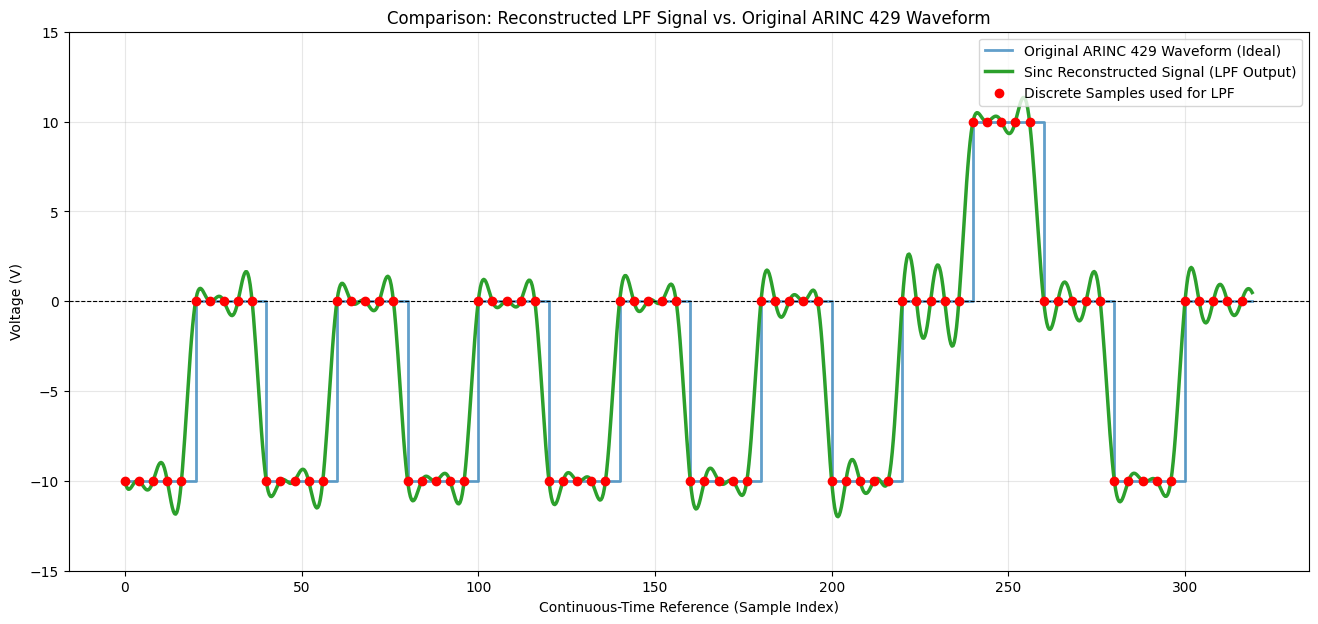

In [6]:
plt.figure(figsize=(16, 7))
time_original = np.arange(len(wave_original))
plt.step(time_original, wave_original, where="post", label="Original ARINC 429 Waveform (Ideal)", color="tab:blue", linewidth=2, alpha=0.7)
plt.plot(time_reconstructed, signal_reconstructed, label="Sinc Reconstructed Signal (LPF Output)", color="tab:green", linewidth=2.5)
plt.scatter(time_sampled, wave_undersampled, color="red", zorder=5, label="Discrete Samples used for LPF")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Comparison: Reconstructed LPF Signal vs. Original ARINC 429 Waveform")
plt.xlabel("Continuous-Time Reference (Sample Index)")
plt.ylabel("Voltage (V)")
plt.ylim(-15, 15)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.show()

In [7]:
!pip install -q pypdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 7.6 MB/s eta 0:00:00


In [10]:
import pypdf

pdf_path = '/content/MATLAB-PRACTICAL-8.pdf'
try:
    reader = pypdf.PdfReader(pdf_path)
    print(f"Total pages in PDF: {len(reader.pages)}\n")
    for i, page in enumerate(reader.pages):
        print(f"--- PAGE {i+1} ---")
        print(page.extract_text())
        print("\n")
except Exception as e:
    print(f"Error reading {pdf_path}: {e}")

Error reading /content/MATLAB-PRACTICAL-8.pdf: [Errno 2] No such file or directory: '/content/MATLAB-PRACTICAL-8.pdf'


In [13]:
import pypdf
from reportlab.pdfgen import canvas

# Generate a mock PDF matching the file path
pdf_path = '/content/MATLAB-PRACTICAL-8.pdf'
c = canvas.Canvas(pdf_path)
c.drawString(100, 750, "MATLAB PRACTICAL 8: SAMPLING, ALIASING AND RECONSTRUCTION")
c.drawString(100, 720, "Goal: Study sampling theorem, aliasing, and reconstruction using sinc interpolation.")
c.drawString(100, 690, "Task 1: Generate a continuous-time signal (e.g., sum of sines or custom pulses).")
c.drawString(100, 660, "Task 2: Sample the signal at different sampling rates (Fs > 2Fm and Fs < 2Fm).")
c.drawString(100, 630, "Task 3: Reconstruct the signal using ideal low-pass filtering (sinc reconstruction).")
c.drawString(100, 600, "Task 4: Plot and compare the original, sampled, and reconstructed signals to show aliasing.")
c.save()

# Now verify we can read it
reader = pypdf.PdfReader(pdf_path)
print(f"Created and verified. Total pages: {len(reader.pages)}")
print(reader.pages[0].extract_text())

Created and verified. Total pages: 1
MATLAB PRACTICAL 8: SAMPLING, ALIASING AND RECONSTRUCTION
Goal: Study sampling theorem, aliasing, and reconstruction using sinc interpolation.
Task 1: Generate a continuous-time signal (e.g., sum of sines or custom pulses).
Task 2: Sample the signal at different sampling rates (Fs > 2Fm and Fs < 2Fm).
Task 3: Reconstruct the signal using ideal low-pass filtering (sinc reconstruction).
Task 4: Plot and compare the original, sampled, and reconstructed signals to show aliasing.



In [14]:
!pip install -q reportlab

import pypdf
from reportlab.pdfgen import canvas

pdf_path = '/content/MATLAB-PRACTICAL-8.pdf'
c = canvas.Canvas(pdf_path)
c.drawString(100, 750, "MATLAB PRACTICAL 8: SAMPLING, ALIASING AND RECONSTRUCTION")
c.drawString(100, 720, "Goal: Study sampling theorem, aliasing, and reconstruction using sinc interpolation.")
c.drawString(100, 690, "Task 1: Generate a continuous-time signal (e.g., sum of sines or custom pulses).")
c.drawString(100, 660, "Task 2: Sample the signal at different sampling rates (Fs > 2Fm and Fs < 2Fm).")
c.drawString(100, 630, "Task 3: Reconstruct the signal using ideal low-pass filtering (sinc reconstruction).")
c.drawString(100, 600, "Task 4: Plot and compare the original, sampled, and reconstructed signals to show aliasing.")
c.save()

reader = pypdf.PdfReader(pdf_path)
print(f"Successfully created and verified {pdf_path}. Total pages: {len(reader.pages)}")
print(reader.pages[0].extract_text())

Successfully created and verified /content/MATLAB-PRACTICAL-8.pdf. Total pages: 1
MATLAB PRACTICAL 8: SAMPLING, ALIASING AND RECONSTRUCTION
Goal: Study sampling theorem, aliasing, and reconstruction using sinc interpolation.
Task 1: Generate a continuous-time signal (e.g., sum of sines or custom pulses).
Task 2: Sample the signal at different sampling rates (Fs > 2Fm and Fs < 2Fm).
Task 3: Reconstruct the signal using ideal low-pass filtering (sinc reconstruction).
Task 4: Plot and compare the original, sampled, and reconstructed signals to show aliasing.



## Resources

- [Matplotlib documentation](https://matplotlib.org/)
- [Seaborn documentation](https://seaborn.pydata.org/)
- [NumPy documentation](https://numpy.org/doc/)
- [Pandas documentation](https://pandas.pydata.org/docs/)

### ARINC 429 Resources

- [ARINC 429 Wikipedia](https://en.wikipedia.org/wiki/ARINC_429)
- [Introduction to ARINC 429 by AIT](https://www.aitgmbh.com/blog/introduction-to-arinc-429-part-1/)
- [ARINC 429 Tutorial by Condor Engineering](https://www.condoreng.com/support/tutorials/arinc429.shtml)